In [5]:
import sys, time
sys.path.append("..")

import joblib
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, f1_score
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline

from src.preprocess import load_data, build_preprocessor
from src.evaluate import log_result

X_train, X_val, y_train, y_val = load_data()
FIG = "../results/figures/"

In [6]:
configs = {
    "nn_10_a1e-4":    dict(hidden_layer_sizes=(10,),   alpha=1e-4),
    "nn_64-32_a1e-4": dict(hidden_layer_sizes=(64, 32), alpha=1e-4),
    "nn_64-32_a1e-3": dict(hidden_layer_sizes=(64, 32), alpha=1e-3),
    "nn_64-32_a1e-2": dict(hidden_layer_sizes=(64, 32), alpha=1e-2),
}

models, preds, f1s = {}, {}, {}
for name, params in configs.items():
    pipe = Pipeline([
        ("prep", build_preprocessor("linear")),
        ("mlp", MLPClassifier(learning_rate_init=0.001, max_iter=100,
                              early_stopping=True, n_iter_no_change=5,
                              random_state=42, **params)),
    ])
    t0 = time.time()
    pipe.fit(X_train, y_train)
    t = time.time() - t0
    preds[name] = log_result(name, pipe, X_train, y_train, X_val, y_val, t)
    models[name] = pipe
    f1s[name] = f1_score(y_val, preds[name], average="micro")

best = max(f1s, key=f1s.get)
print("best:", best, round(f1s[best], 4))

{'model': 'nn_10_a1e-4', 'train_micro_f1': 0.6782, 'val_micro_f1': 0.6847, 'val_macro_f1': 0.6075, 'train_time_sec': 10.3}
{'model': 'nn_64-32_a1e-4', 'train_micro_f1': 0.695, 'val_micro_f1': 0.694, 'val_macro_f1': 0.6183, 'train_time_sec': 24.2}
{'model': 'nn_64-32_a1e-3', 'train_micro_f1': 0.6956, 'val_micro_f1': 0.695, 'val_macro_f1': 0.6315, 'train_time_sec': 30.9}
{'model': 'nn_64-32_a1e-2', 'train_micro_f1': 0.6959, 'val_micro_f1': 0.6941, 'val_macro_f1': 0.6255, 'train_time_sec': 27.4}
best: nn_64-32_a1e-3 0.695


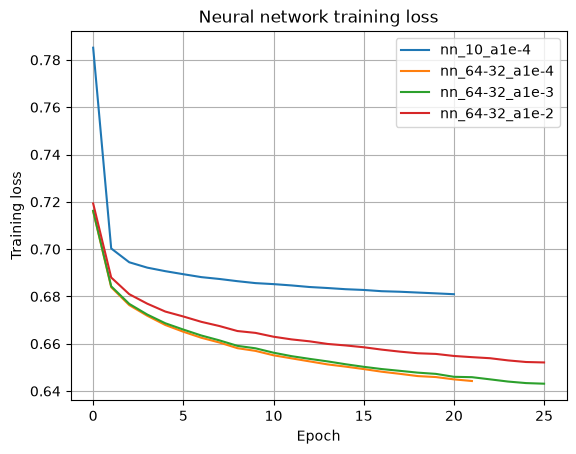

In [7]:
for name, pipe in models.items():
    plt.plot(pipe.named_steps["mlp"].loss_curve_, label=name)
plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title("Neural network training loss")
plt.legend()
plt.grid(True)
plt.savefig(FIG + "08_nn_loss_curves.png", dpi=150, bbox_inches="tight")
plt.show()

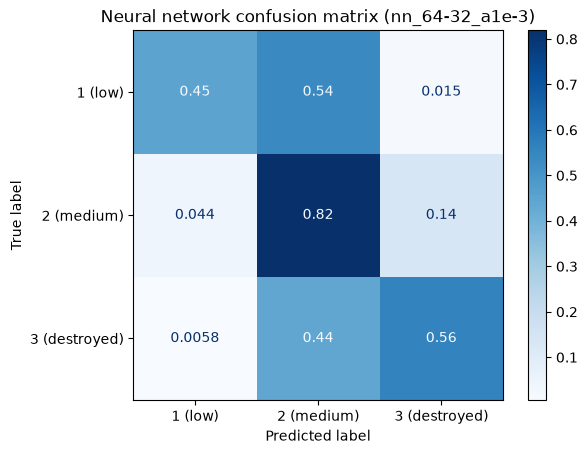

['../models/nn.joblib']

In [8]:
ConfusionMatrixDisplay.from_predictions(
    y_val, preds[best], normalize="true", cmap="Blues",
    display_labels=["1 (low)", "2 (medium)", "3 (destroyed)"])
plt.title(f"Neural network confusion matrix ({best})")
plt.savefig(FIG + "09_nn_confusion.png", dpi=150, bbox_inches="tight")
plt.show()

joblib.dump(models[best], "../models/nn.joblib")

In [9]:
import pandas as pd
df = pd.read_csv("results/results.csv")
df = df.drop(index=1)   # the mislabelled knn_tuned row (k=15 numbers)
df = df.drop_duplicates(subset=["model", "val_micro_f1", "val_macro_f1"], keep="last")
df.to_csv("results/results.csv", index=False)
print(df)

FileNotFoundError: [Errno 2] No such file or directory: 'results/results.csv'